In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
%matplotlib inline

In [6]:
df = pd.read_csv("bestsellers-with-categories_1_.csv")

In [7]:
display(df.head())

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


In [8]:
print("Розмір датасету:", df.shape)

Розмір датасету: (550, 7)


Відповідь: 550

In [9]:
df.columns = ['name', 'author', 'user_rating', 'reviews', 'price', 'year', 'genre']

In [10]:
print(df.isna().sum())

name           0
author         0
user_rating    0
reviews        0
price          0
year           0
genre          0
dtype: int64


In [11]:
print(df['genre'].unique())

['Non Fiction' 'Fiction']


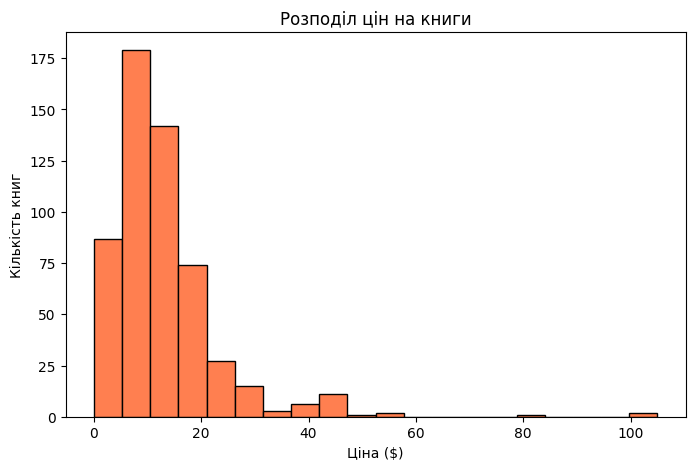

In [12]:
df['price'].plot(kind='hist', bins=20, color='coral', edgecolor='black', figsize=(8, 5))
plt.title('Розподіл цін на книги')
plt.xlabel('Ціна ($)')
plt.ylabel('Кількість книг')
plt.show()

In [13]:
max_price = df['price'].max()
min_price = df['price'].min()
mean_price = df['price'].mean()
median_price = df['price'].median()

In [14]:
print(f"Макс: {max_price}, Мін: {min_price}, Середня: {mean_price:.2f}, Медіана: {median_price}")

Макс: 105, Мін: 0, Середня: 13.10, Медіана: 11.0


Максимальна ціна? Відповідь: 105
Мінімальна ціна? Відповідь: 0
Середня ціна? Відповідь: 13.10
Медіанна ціна? Відповідь: 11

In [15]:
max_rating = df['user_rating'].max()
print("Найвищий рейтинг:", max_rating)

Найвищий рейтинг: 4.9


In [16]:
books_with_max_rating = len(df[df['user_rating'] == max_rating])
print("Кількість книг з найвищим рейтингом:", books_with_max_rating)

Кількість книг з найвищим рейтингом: 52


In [17]:
max_reviews_index = df['reviews'].idxmax()
best_reviewed_book = df.loc[max_reviews_index, 'name']
print("Книга з найбільшою кількістю відгуків:", best_reviewed_book)

Книга з найбільшою кількістю відгуків: Where the Crawdads Sing


In [18]:
df_2015 = df[df['year'] == 2015]
most_expensive_2015 = df_2015.loc[df_2015['price'].idxmax(), 'name']
print("Найдорожча книга у 2015 році:", most_expensive_2015)

Найдорожча книга у 2015 році: Publication Manual of the American Psychological Association, 6th Edition


In [19]:
fiction_2010 = len(df[(df['genre'] == 'Fiction') & (df['year'] == 2010)])
print("Кількість книг Fiction у 2010 році:", fiction_2010)

Кількість книг Fiction у 2010 році: 20


In [20]:
top_rated_10_11 = len(df[(df['user_rating'] == 4.9) & (df['year'].isin([2010, 2011]))])
print("Книг з рейтингом 4.9 у 2010-2011 роках:", top_rated_10_11)

Книг з рейтингом 4.9 у 2010-2011 роках: 1


In [21]:
cheap_2015 = df[(df['year'] == 2015) & (df['price'] < 8)].sort_values(by='price')

In [22]:
last_book = cheap_2015.iloc[-1]['name']
print("Остання книга у відсортованому списку:", last_book)

Остання книга у відсортованому списку: Old School (Diary of a Wimpy Kid #10)


In [23]:
genre_prices = df.groupby('genre').agg({'price': ['min', 'max']})
display(genre_prices)

price     
              min  max
genre                 
Fiction         0   82
Non Fiction     0  105

Максимальна ціна для жанру Fiction: 82
Мінімальна ціна для жанру Fiction: 0
Максимальна ціна для жанру Non Fiction: 105
Мінімальна ціна для жанру Non Fiction: 0

In [24]:
author_books_count = df.groupby('author').agg({'name': 'count'})

In [25]:
author_books_count = author_books_count.rename(columns={'name': 'books_count'})

In [26]:
print("Розмірність таблиці:", author_books_count.shape)

Розмірність таблиці: (248, 1)


In [27]:
top_author = author_books_count['books_count'].idxmax()
top_author_count = author_books_count['books_count'].max()
print(f"Автор з найбільшою кількістю книг: {top_author} ({top_author_count} книг)")

Автор з найбільшою кількістю книг: Jeff Kinney (12 книг)


Якої розмірності вийшла таблиця? - 248
Який автор має найбільше книг? - Jeff Kinney
Скільки книг цього автора? - 12


In [28]:
author_avg_rating = df.groupby('author').agg({'user_rating': 'mean'})

In [29]:
author_avg_rating = author_avg_rating.rename(columns={'user_rating': 'avg_rating'})

In [30]:
worst_author = author_avg_rating['avg_rating'].idxmin()
worst_author_rating = author_avg_rating['avg_rating'].min()
print(f"\nАвтор з мінімальним середнім рейтингом: {worst_author} (рейтинг {worst_author_rating})")


Автор з мінімальним середнім рейтингом: Donna Tartt (рейтинг 3.9)


У якого автора середній рейтинг мінімальний? - Donna Tartt
Який у цього автора середній рейтинг? - 3.9

In [31]:
author_stats = pd.concat([author_books_count, author_avg_rating], axis=1)

In [32]:
author_stats_sorted = author_stats.sort_values(by=['books_count', 'avg_rating'])

In [33]:
print("\nВідсортована загальна таблиця авторів")
display(author_stats_sorted.head())


Відсортована загальна таблиця авторів


,books_count,avg_rating
author,,
Muriel Barbery,1,4.0
Chris Cleave,1,4.1
Ian K. Smith M.D.,1,4.1
Pierre Dukan,1,4.1
Elizabeth Strout,1,4.2


In [34]:
first_author_in_list = author_stats_sorted.index[0]
print("Перший автор у відсортованому списку:", first_author_in_list)

Перший автор у відсортованому списку: Muriel Barbery


Який автор перший у списку? - Muriel Barbery

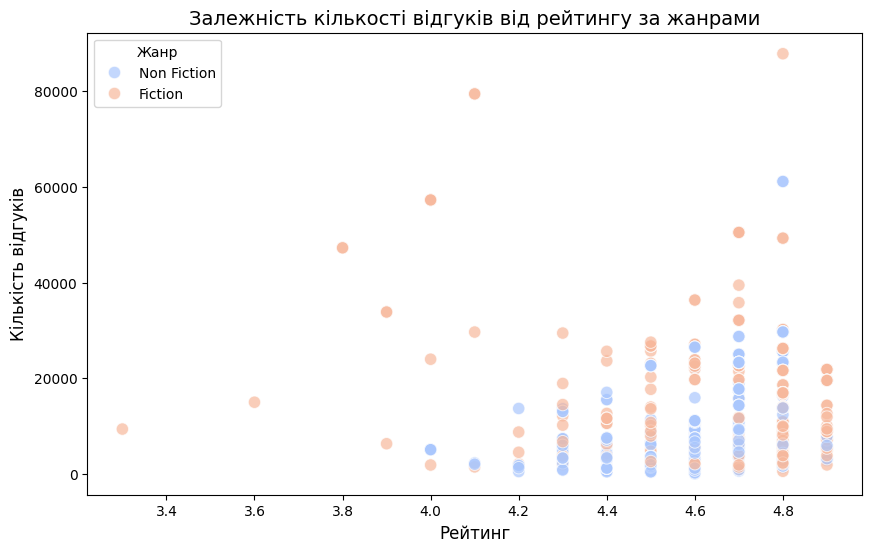

In [37]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='user_rating', y='reviews', hue='genre', data=df, palette='coolwarm', alpha=0.7, s=80)
plt.title('Залежність кількості відгуків від рейтингу за жанрами', fontsize=14)
plt.xlabel('Рейтинг', fontsize=12)
plt.ylabel('Кількість відгуків', fontsize=12)
plt.legend(title='Жанр')
plt.show()

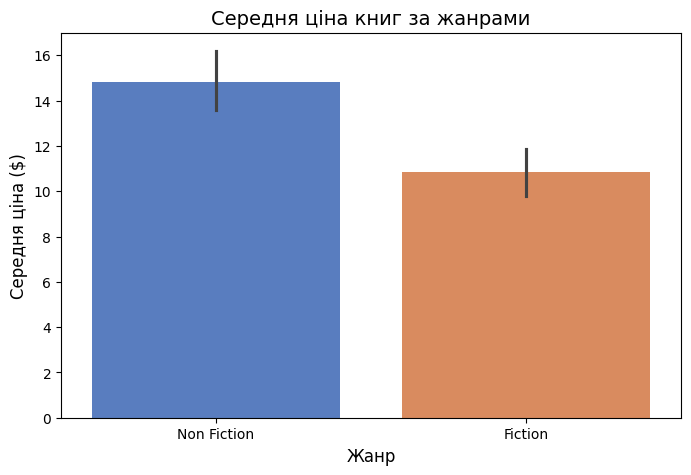

In [43]:
plt.figure(figsize=(8, 5))
sns.barplot(x='genre', y='price', data=df, palette='muted', hue='genre', legend=False)
plt.title('Середня ціна книг за жанрами', fontsize=14)
plt.xlabel('Жанр', fontsize=12)
plt.ylabel('Середня ціна ($)', fontsize=12)
plt.show()

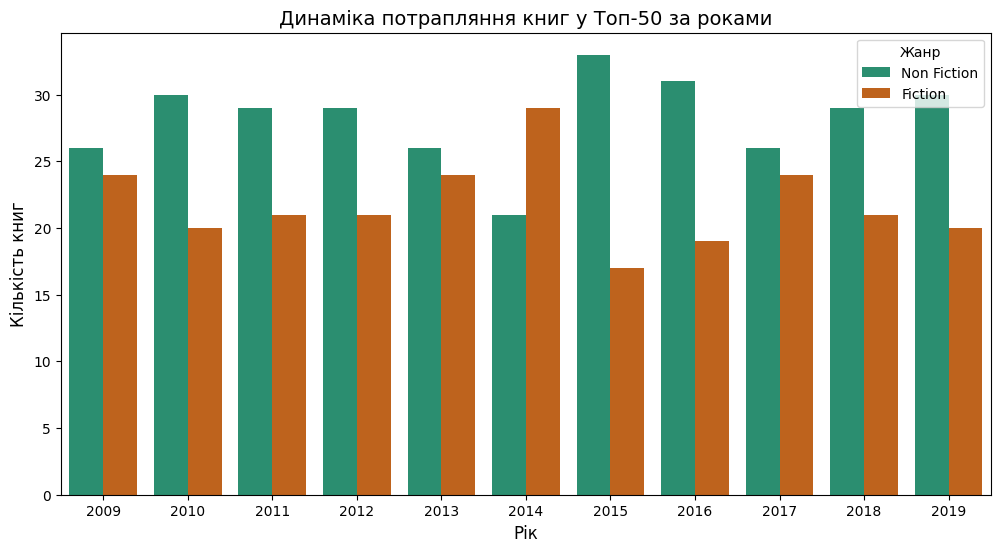

In [39]:
plt.figure(figsize=(12, 6))
sns.countplot(x='year', hue='genre', data=df, palette='Dark2')
plt.title('Динаміка потрапляння книг у Топ-50 за роками', fontsize=14)
plt.xlabel('Рік', fontsize=12)
plt.ylabel('Кількість книг', fontsize=12)
plt.legend(title='Жанр')
plt.show()